# STEP 1: 1D Linear Convection

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


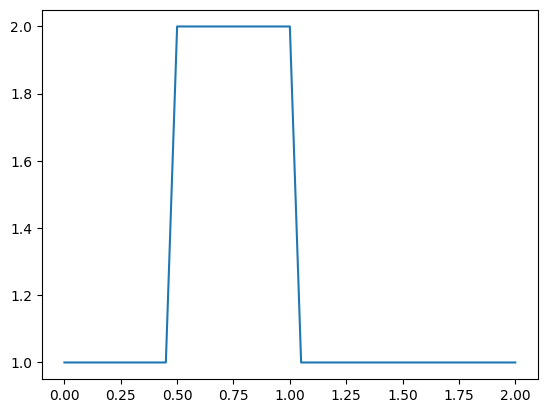

In [33]:
import numpy
from matplotlib import pyplot
import time, sys

%matplotlib inline

nx = 41
dx = 2 /(nx-1)
nt = 25
dt = .025
c = 1

u = numpy.ones(nx)
u[int(.5 /dx):int(1/dx+1)] = 2
print(u)

pyplot.plot(numpy.linspace(0,2, nx), u);

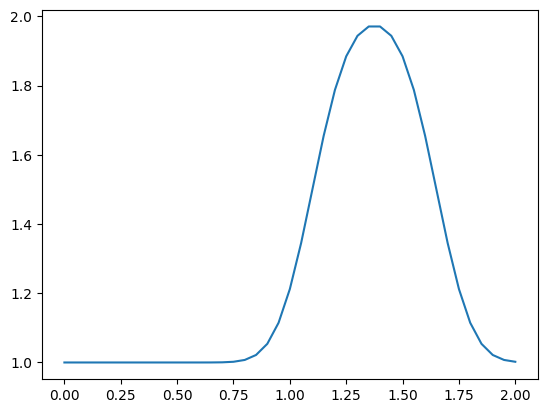

In [34]:
un = numpy.ones(nx)

for n in range(nt):
    un = u.copy()
    for i in range(1,nx):
    #for u in range(nx):
        u[i] = un[i] - c * dt / dx *(un[i] - un[i-1])

pyplot.plot(numpy.linspace(0,2, nx),u)



# Step 2: Nonlinear Convention

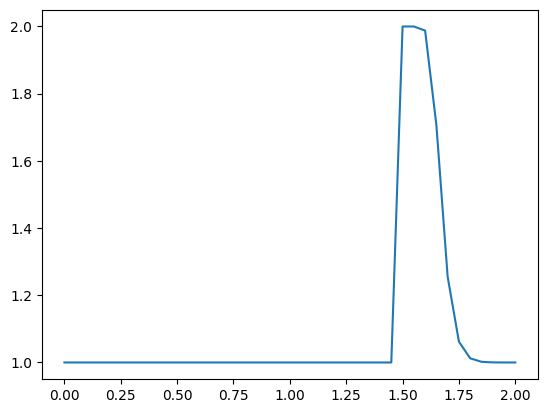

In [35]:
import numpy
from matplotlib import pyplot
%matplotlib inline

nx = 41
dx = 2 / (nx - 1)
nt = 20
dt = .025

u = numpy.ones(nx)
u[int(.5 /dx) : int(1 / dx + 1)] = 2

un = numpy.ones(nx)

for n in range(nt):
    un = u.copy()
    for i in range(1, nx):

        u[i] = un[i] - un[i] * dt/ dx *(un[i] - un[i-1])

pyplot.plot(numpy.linspace(0,2,nx), u)


# Step 3: Diffusion Equation in 1-D

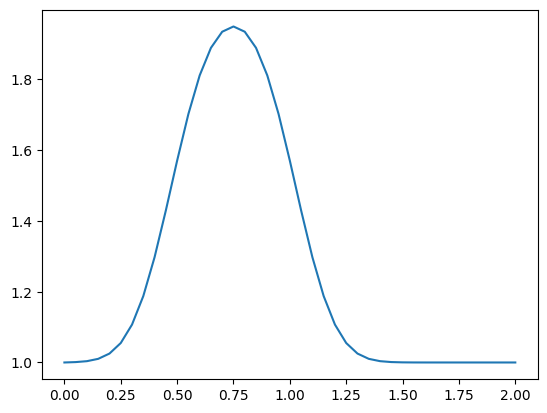

In [36]:
import numpy
from matplotlib import pyplot
%matplotlib inline

nx = 41
dx = 2 / (nx - 1)
nt = 20
nu = 0.3

sigma = .2
dt = sigma * dx**2 / nu

u = numpy.ones(nx)
u[int(.5 /dx) : int(1 / dx + 1)] = 2

un = numpy.ones(nx)

for n in range(nt):
    un = u.copy()
    for i in range(1, nx-1):
        u[i] = un[i] + nu * dt / dx**2 * (un[i+1] - 2 * un[i] + un[i-1])

pyplot.plot(numpy.linspace(0,2,nx), u);


# Step 4: Burgers' equation

In [37]:
import numpy
import sympy

from sympy import init_printing
init_printing(use_latex=True)

x, nu, t = sympy.symbols('x nu t')
phi = sympy.exp(-(x-4*t)**2/ (4* nu *(t+1))) + sympy.exp(-(x-4*t-2 *sympy.pi)**2 / (4* nu *(t+1))) 

phi

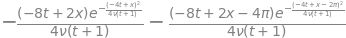

In [38]:
phiprime = phi.diff(x)
phiprime

In [39]:
print(phiprime)

-(-8*t + 2*x)*exp(-(-4*t + x)**2/(4*nu*(t + 1)))/(4*nu*(t + 1)) - (-8*t + 2*x - 4*pi)*exp(-(-4*t + x - 2*pi)**2/(4*nu*(t + 1)))/(4*nu*(t + 1))


In [40]:
from sympy.utilities.lambdify import lambdify

u = -2 * nu * (phiprime / phi) + 4
print(u)

-2*nu*(-(-8*t + 2*x)*exp(-(-4*t + x)**2/(4*nu*(t + 1)))/(4*nu*(t + 1)) - (-8*t + 2*x - 4*pi)*exp(-(-4*t + x - 2*pi)**2/(4*nu*(t + 1)))/(4*nu*(t + 1)))/(exp(-(-4*t + x - 2*pi)**2/(4*nu*(t + 1))) + exp(-(-4*t + x)**2/(4*nu*(t + 1)))) + 4


In [41]:
ufunc = lambdify ((t, x, nu),u)
print(ufunc(1, 4, 3))

3.49170664206445


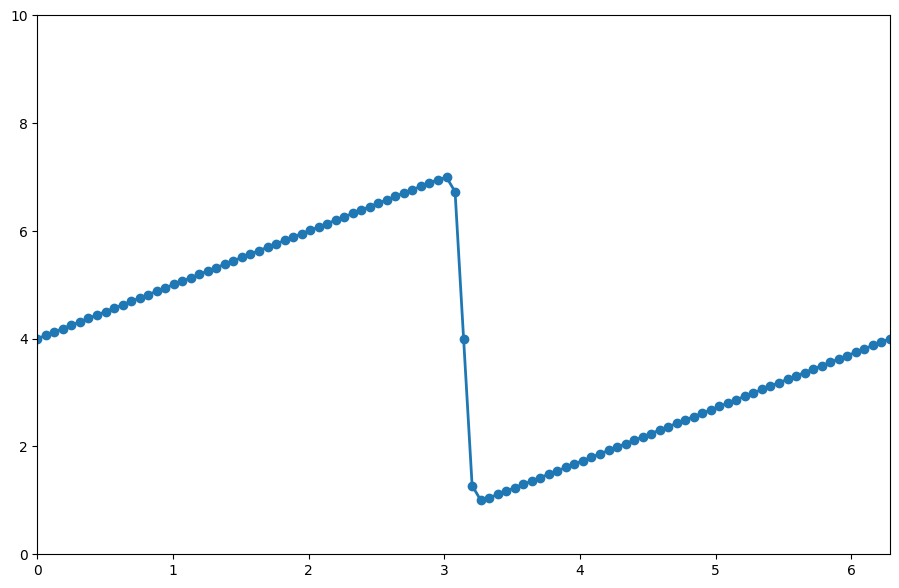

In [43]:
from matplotlib import pyplot
%matplotlib inline

nx = 101
nt = 100
dx = 2* numpy.pi / (nx - 1)
nu = 0.07
dt = dx * nu

x = numpy.linspace(0, 2 * numpy.pi, nx)
un = numpy.empty(nx)
t = 0

u = numpy.asarray([ufunc(t, x0,nu) for x0 in x])
u

pyplot.figure(figsize=(11,7), dpi = 100)
pyplot.plot(x, u, marker = 'o', lw =2)
pyplot.xlim([0, 2 * numpy.pi])
pyplot.ylim([0, 10]);

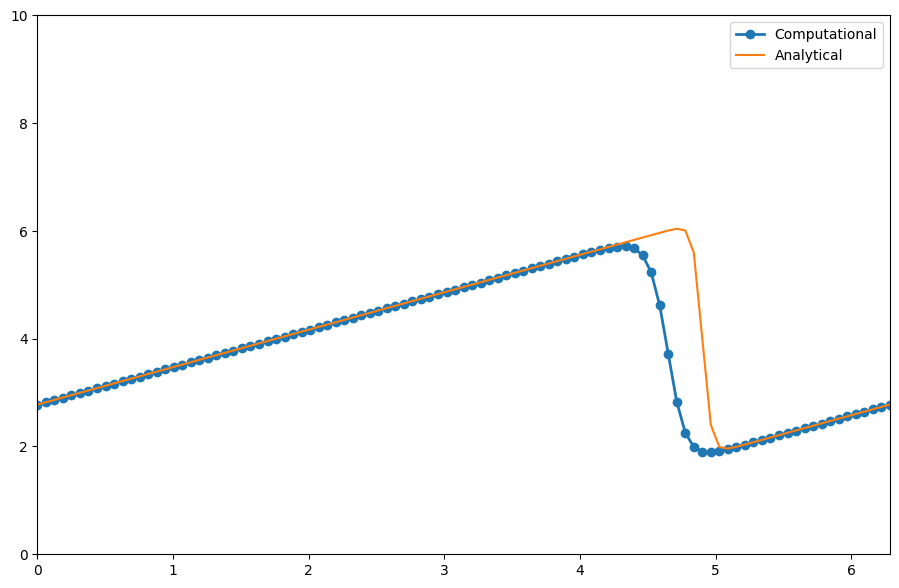

In [44]:
for n in range(nt):
    un = u.copy()
    for i in range(1, nx-1):
        u[i] = un[i] - un[i] * dt/ dx * (un[i] - un[i-1]) + nu * dt / dx**2 *\
        (un[i+1] - 2*un[i] +un[i-1])
    
    u[0] = un[0] - un[0] * dt / dx * (un[0] - un[-2]) + nu * dt / dx**2 *\
        (un[1] - 2* un[0] + un[-2])

    u[-1] = u[0]

u_analytical = numpy.asarray([ufunc(nt* dt, xi, nu) for xi in x])

pyplot.figure(figsize = (11, 7), dpi = 100)
pyplot.plot(x, u, marker = 'o', lw =2, label = 'Computational')
pyplot.plot(x, u_analytical, label = 'Analytical')
pyplot.xlim([0, 2 * numpy.pi])
pyplot.ylim([0, 10])
pyplot.legend();